## Interval Analysis

In [ ]:
# !pip install tensorboardX

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
import numpy as np
import time
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
# from tensorboardX import SummaryWriter

use_cuda = False
device = torch.device("cuda" if use_cuda else "cpu")
batch_size = 64

np.random.seed(42)
torch.manual_seed(42)


## Dataloaders
train_dataset = datasets.MNIST('mnist_data/', train=True, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))
test_dataset = datasets.MNIST('mnist_data/', train=False, download=True, transform=transforms.Compose(
    [transforms.ToTensor()]
))

train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## Simple NN. You can change this if you want. If you change it, mention the architectural details in your report.
class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc = nn.Linear(28*28, 200)
        self.fc2 = nn.Linear(200,10)

    def forward(self, x):
        x = x.view((-1, 28*28))
        x = F.relu(self.fc(x))
        x = self.fc2(x)
        x = F.softmax(x, dim=-1) # added softmax for probabilities
        return x

class Normalize(nn.Module):
    def forward(self, x):
        return (x - 0.1307)/0.3081

# Add the data normalization as a first "layer" to the network
# this allows us to search for adverserial examples to the real image, rather than
# to the normalized image
model = nn.Sequential(Normalize(), Net())

model = model.to(device)
model.train()


100%|██████████| 9.91M/9.91M [00:00<00:00, 60.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 14.9MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.52MB/s]


Sequential(
  (0): Normalize()
  (1): Net(
    (fc): Linear(in_features=784, out_features=200, bias=True)
    (fc2): Linear(in_features=200, out_features=10, bias=True)
  )
)

In [ ]:
def train_model(model, num_epochs):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(model.parameters(), lr=0.001, momentum=0.9)

    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        for i, data in enumerate(train_loader, 0):
            images, labels = data
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        print(f'Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader):.3f}')

def test_model(model):
    model.eval()
    with torch.no_grad():
        correct = 0
        total = 0
        for data in test_loader:
            images, labels = data
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
        print(f'Accuracy on images: {100 * correct / total}')

In [ ]:
train_model(model, 15)
test_model(model)

Epoch 1/15, Loss: 2.012
Epoch 2/15, Loss: 1.729
Epoch 3/15, Loss: 1.627
Epoch 4/15, Loss: 1.596
Epoch 5/15, Loss: 1.582
Epoch 6/15, Loss: 1.572
Epoch 7/15, Loss: 1.566
Epoch 8/15, Loss: 1.561
Epoch 9/15, Loss: 1.557
Epoch 10/15, Loss: 1.553
Epoch 11/15, Loss: 1.550
Epoch 12/15, Loss: 1.547
Epoch 13/15, Loss: 1.545
Epoch 14/15, Loss: 1.542
Epoch 15/15, Loss: 1.540
Accuracy on images: 93.43


### Interval analysis


For each raw image, start with $[\max(0,x-\epsilon),\min(1,x+\epsilon)]$.

I used the [hint's affine interval rule](https://github.com/Zinoex/bound_propagation/blob/main/src/bound_propagation/linear.py):
with $c=(\ell+u)/2$ and $r=(u-\ell)/2$,
$$\ell'=Wc+b-|W|r,\qquad u'=Wc+b+|W|r.$$ ReLU is applied to both endpoints. Since softmax preserves class ordering,
$f_y-f_j\ge0$ is equivalent to $z_y-z_j\ge0$ for the pre-softmax scores $z$.

Later these differences are bounded directly and verified each correctly classified image
when all nine lower bounds are nonnegative.

In [ ]:
import copy
import pandas as pd
from IPython.display import display

def pixel_bounds(x, epsilon):
    return (x - epsilon).clamp(0, 1), (x + epsilon).clamp(0, 1)

def affine_bounds(lower, upper, weight, bias):
    center, radius = (lower + upper) / 2, (upper - lower) / 2
    out_center = (weight @ center.unsqueeze(-1)).squeeze(-1) + bias
    out_radius = (weight.abs() @ radius.unsqueeze(-1)).squeeze(-1)
    return out_center - out_radius, out_center + out_radius

def relu_bounds(lower, upper):
    return lower.clamp(min=0), upper.clamp(min=0)

def competing_classes(labels, classes=10):
    competitors = torch.arange(classes, device=labels.device).expand(len(labels), -1)
    return competitors[competitors != labels[:, None]].reshape(len(labels), classes - 1)

@torch.no_grad()
def margin_bounds(model, x, labels, epsilon):
    lower, upper = pixel_bounds(x, epsilon)
    lower, upper = model[0](lower).flatten(1), model[0](upper).flatten(1)
    lower, upper = affine_bounds(lower, upper, model[1].fc.weight, model[1].fc.bias)
    lower, upper = relu_bounds(lower, upper)
    final = model[1].fc2
    competitors = competing_classes(labels, final.out_features)
    weight = final.weight[labels, None, :] - final.weight[competitors]
    bias = final.bias[labels, None] - final.bias[competitors]
    margin_lower, margin_upper = affine_bounds(lower, upper, weight, bias)
    return margin_lower, margin_upper, competitors

@torch.no_grad()
def verify_test_set(model, test_loader, epsilons):
    model.eval()
    parameter = next(model.parameters())
    masks, minimum_bounds, predictions, targets = [], [], [], []
    for images, labels in test_loader:
        images = images.to(device=parameter.device, dtype=parameter.dtype)
        labels = labels.to(parameter.device)
        predicted = model(images).argmax(1)
        correct = predicted.eq(labels)
        batch_masks, batch_bounds = [], []
        for epsilon in epsilons:
            lower, _, _ = margin_bounds(model, images, labels, epsilon)
            minimum = lower.amin(1)
            batch_masks.append(correct & (minimum >= 0))
            batch_bounds.append(minimum)
        masks.append(torch.stack(batch_masks, 1).cpu())
        minimum_bounds.append(torch.stack(batch_bounds, 1).cpu())
        predictions.append(predicted.cpu())
        targets.append(labels.cpu())
    return (torch.cat(masks), torch.cat(minimum_bounds),
            torch.cat(predictions), torch.cat(targets))

### Verified accuracy

Evaluated all 10,000 test images at the ten required radii.

In [ ]:
verification_model = copy.deepcopy(model).double().eval()
epsilons = [i / 100 for i in range(1, 11)]
masks, minimum_bounds, predictions, labels = verify_test_set(
    verification_model, test_loader, epsilons
)
clean_correct = predictions.eq(labels)
clean_accuracy = 100 * clean_correct.sum().item() / len(labels)

results = pd.DataFrame({
    "epsilon": epsilons,
    "verified_count": masks.sum(0).numpy(),
    "verified_accuracy_percent": 100 * masks.sum(0).numpy() / len(labels),
})
display(results.style.format({"epsilon": "{:.2f}", "verified_accuracy_percent": "{:.2f}"}).hide(axis="index"))

epsilon,verified_count,verified_accuracy_percent
0.01,7055,70.55
0.02,2368,23.68
0.03,456,4.56
0.04,58,0.58
0.05,2,0.02
0.06,0,0.00
0.07,0,0.00
0.08,0,0.00
0.09,0,0.00
0.10,0,0.00


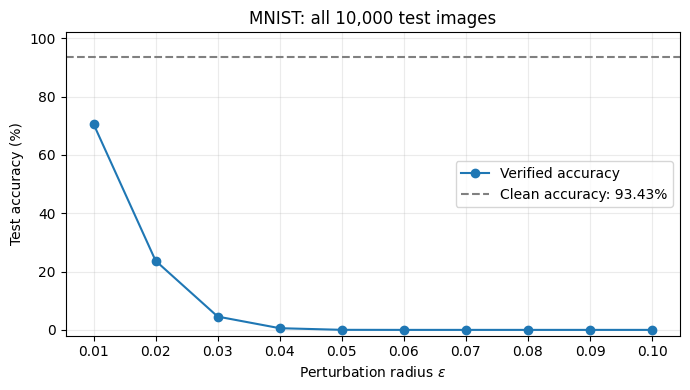

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(results.epsilon, results.verified_accuracy_percent, "o-", label="Verified accuracy")
ax.axhline(clean_accuracy, color="gray", linestyle="--", label=f"Clean accuracy: {clean_accuracy:.2f}%")
ax.set(xlabel=r"Perturbation radius $\epsilon$", ylabel="Test accuracy (%)",
       xticks=results.epsilon, ylim=(-2, 102), title="MNIST: all 10,000 test images")
ax.grid(alpha=0.25)
ax.legend(loc="center right")
fig.tight_layout()
plt.show()

### Observations

The verified accuracy decreases from 70.55% at ε = 0.01 to 0% at ε = 0.06.

### Interpretations

As the perturbation radius increases, the propagated intervals widen, reducing the verified accuracy from 70.55% at ε = 0.01 to 0% at ε ≥ 0.06. However, failure to certify an image does not necessarily imply that it is non-robust, since interval analysis may overapproximate the possible network outputs.